# Cancellation classification: EDA and input preparation
**Prediction point:** immediately after booking creation. **Target:** `IsCanceled` (1 = canceled).

This notebook performs training-only cancellation EDA, selects original booking-time inputs, splits rows chronologically, and exports CSVs. It does not fit preprocessing or a classifier. General cleaning remains in `general_EDA.ipynb`.

Next, open `classification_model.ipynb` to fit imputation, scaling, encoding, and logistic regression together in one pipeline. The model notebook is supplied unexecuted so training starts when you run it.


In [4]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/data/processed_EDA/H2_cleaned.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from within Hotel_demand_ML')
DATA_PATH = ROOT / 'src/data/processed_EDA/H2_cleaned.csv'
OUTPUT_DIR = ROOT / 'src/data/classification_features/basic'
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].str.strip()
assert df.IsCanceled.notna().all() and set(df.IsCanceled.unique()) == {0, 1}
y = df.IsCanceled.astype(int)
print('Source shape:', df.shape)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR = OUTPUT_DIR / 'plots'
PLOT_DIR.mkdir(exist_ok=True)
def finish_plot(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

FileNotFoundError: Run this notebook from within Hotel_demand_ML

## 1. Keep only inputs plausibly available at booking
Drop direct outcome leakage (`ReservationStatus`, `ReservationStatusDate`) and later operational information (`AssignedRoomType`, `BookingChanges`, `DaysInWaitingList`). Exclude ADR, parking, and request counts conservatively until their initial values can be verified. Agent is a category, not a numeric magnitude; zero means no recorded agent, not necessarily a direct booking.

Retain original lead time, stay-night counts, guest counts, history, booking categories, and arrival year/month/day. Month is categorical so we do not impose a numeric distance from January to December. Week number is omitted to avoid another overlapping calendar representation. Day of month and year are kept as simple numeric inputs for this first baseline; their linear effects are only an approximation.

All retained fields must describe booking-time values; that assumption cannot be proven from a final-state CSV. No features derived from later events are used.

In [3]:
CATEGORICAL = ['Meal', 'Country', 'MarketSegment', 'DistributionChannel',
               'ReservedRoomType', 'DepositType', 'Agent', 'CustomerType']
NUMERIC = ['LeadTime', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults',
           'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations',
           'PreviousBookingsNotCanceled']
DATE_INPUTS = ['ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateDayOfMonth']
INPUT_COLUMNS = NUMERIC + CATEGORICAL + DATE_INPUTS
EXCLUDED = {
    'IsCanceled': 'Target only',
    'ReservationStatus': 'Direct outcome leakage',
    'ReservationStatusDate': 'Outcome timestamp',
    'AssignedRoomType': 'Room assignment can happen later',
    'BookingChanges': 'Changes accumulated after creation',
    'DaysInWaitingList': 'Waiting duration is not known at initial creation',
    'ADR': 'Initial quoted rate unavailable in this snapshot',
    'RequiredCarParkingSpaces': 'Initial request snapshot unavailable',
    'TotalOfSpecialRequests': 'Initial request snapshot unavailable',
    'ArrivalDateWeekNumber': 'Replaced by cyclical month and weekday features',
}
assert set(df.columns) == set(INPUT_COLUMNS) | set(EXCLUDED)
display(pd.Series(EXCLUDED, name='Reason').rename_axis('Excluded column').to_frame())
# Use original columns only: no engineered ratios, sums, logs, or flags.
MODEL_CATEGORICAL = CATEGORICAL + ['ArrivalDateMonth']
MODEL_NUMERIC = NUMERIC + ['ArrivalDateYear', 'ArrivalDateDayOfMonth']
MODEL_COLUMNS = MODEL_NUMERIC + MODEL_CATEGORICAL
X = df[MODEL_COLUMNS].copy()
for col in MODEL_CATEGORICAL:
    X[col] = X[col].map(lambda value: str(value).strip() if pd.notna(value) else np.nan).astype(object)
assert 'IsCanceled' not in X.columns
assert not set(EXCLUDED).intersection(X.columns)

NameError: name 'df' is not defined

## 2. Split before exploring relationships with cancellation
Preserve the earlier chronological boundaries near 60%/80% of inferred booking dates, so future bookings do not guide training. Booking date = arrival date minus lead time. This date and scheduled checkout are **split metadata only**, not model features.

Training bookings must have scheduled checkout before validation begins; validation bookings must have checkout before test begins. This conservative label-maturity rule reduces the cohorts and changes their composition. Checkout is only a proxy for when outcomes become available. All plots below use the resulting training cohort; validation and test do not guide feature selection.

The input is bounded by arrival date, so recent booking cohorts may omit future stays. Dates can also be affected by amendments. Use actual booking snapshots and complete follow-up for production validation.

In [3]:
MONTHS = {name: i for i, name in enumerate(calendar.month_name) if name}

def booking_dates(raw):
    month = raw.ArrivalDateMonth.map(MONTHS)
    if month.isna().any():
        raise ValueError('Unknown arrival month')
    arrival = pd.to_datetime(dict(year=raw.ArrivalDateYear, month=month,
                                 day=raw.ArrivalDateDayOfMonth), errors='raise')
    booking = arrival - pd.to_timedelta(raw.LeadTime, unit='D')
    return arrival, booking


arrival_dates, booking_date = booking_dates(df)
label_ready_date = arrival_dates + pd.to_timedelta(
    df.StaysInWeekendNights + df.StaysInWeekNights, unit='D')
sorted_dates = booking_date.sort_values().reset_index(drop=True)
validation_start = sorted_dates.iloc[int(len(df) * 0.60)]
test_start = sorted_dates.iloc[int(len(df) * 0.80)]
base_train = booking_date.lt(validation_start)
base_valid = booking_date.ge(validation_start) & booking_date.lt(test_start)
masks = {
    'train': base_train & label_ready_date.lt(validation_start),
    'validation': base_valid & label_ready_date.lt(test_start),
    'test': booking_date.ge(test_start),
}
splits = {name: (X.loc[mask].copy(), y.loc[mask].copy()) for name, mask in masks.items()}
X_train, y_train = splits['train']
X_valid, y_valid = splits['validation']
X_test, y_test = splits['test']
summary = []
for name, mask in masks.items():
    assert mask.any() and y[mask].nunique() == 2
    summary.append({'split': name, 'rows': int(mask.sum()),
                    'booking_from': booking_date[mask].min(), 'booking_to': booking_date[mask].max(),
                    'cancellation_rate': y[mask].mean()})
assert booking_date[masks['train']].max() < booking_date[masks['validation']].min()
assert booking_date[masks['validation']].max() < booking_date[masks['test']].min()
assert sum(mask.astype(int) for mask in masks.values()).max() == 1
split_summary = pd.DataFrame(summary)
display(split_summary)
print('Training rows purged:', int(base_train.sum() - masks['train'].sum()))
print('Validation rows purged:', int(base_valid.sum() - masks['validation'].sum()))
eda = df.loc[masks['train']].copy()
training_rate = eda.IsCanceled.mean()
print('EDA cohort:', len(eda), 'training bookings only')

,split,rows,booking_from,booking_to,cancellation_rate
0,train,26375,2014-10-17,2016-10-02,0.264000
1,validation,4157,2016-10-03,2017-01-29,0.254270
2,test,10740,2017-01-31,2017-08-30,0.293482


Training rows purged: 5584
Validation rows purged: 6419
EDA cohort: 26375 training bookings only


## 3. Cancellation balance
Show both counts and proportions. The majority-class accuracy is a reference, not sufficient evidence of model quality. Cancellation precision, recall, F1, average precision, and ROC-AUC will be useful when we train a model. We do not apply SMOTE or class weighting automatically.

,Bookings,Share
IsCanceled,,
0,19412,0.736
1,6963,0.264


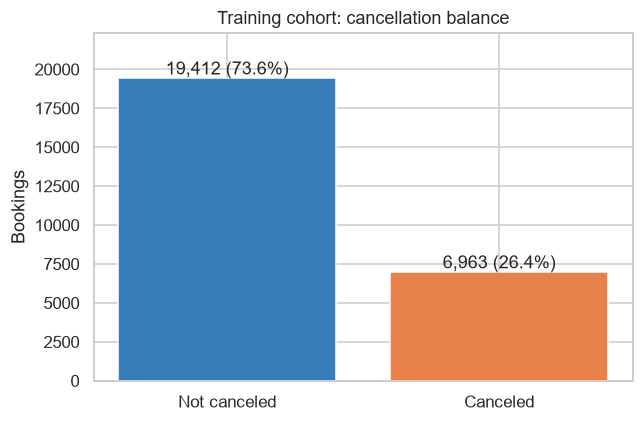

Majority-class accuracy reference: 73.6%


In [4]:
balance = eda.IsCanceled.value_counts().reindex([0, 1], fill_value=0)
balance_table = pd.DataFrame({'Bookings': balance, 'Share': balance / balance.sum()})
display(balance_table.rename_axis('IsCanceled'))
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Not canceled', 'Canceled'], balance.values, color=['#377eb8', '#e88049'])
for bar, count in zip(bars, balance.values):
    ax.text(bar.get_x()+bar.get_width()/2, count, f'{count:,} ({count/len(eda):.1%})', ha='center', va='bottom')
ax.set(title='Training cohort: cancellation balance', ylabel='Bookings', ylim=(0, balance.max()*1.15))
finish_plot('class_balance')
print(f'Majority-class accuracy reference: {balance.max()/balance.sum():.1%}')

## 4. Numeric correlation heatmap
Pearson correlations describe linear associations. For a numeric feature and a binary target, this is the point-biserial correlation. The sign indicates direction; magnitude does not establish causation, predictive importance, or absence of nonlinear relationships. Correlations between predictors can reveal redundancy.

Agent IDs and other categories are excluded because their numerical codes have no quantitative meaning. We do not remove predictors solely because their target correlation is weak.

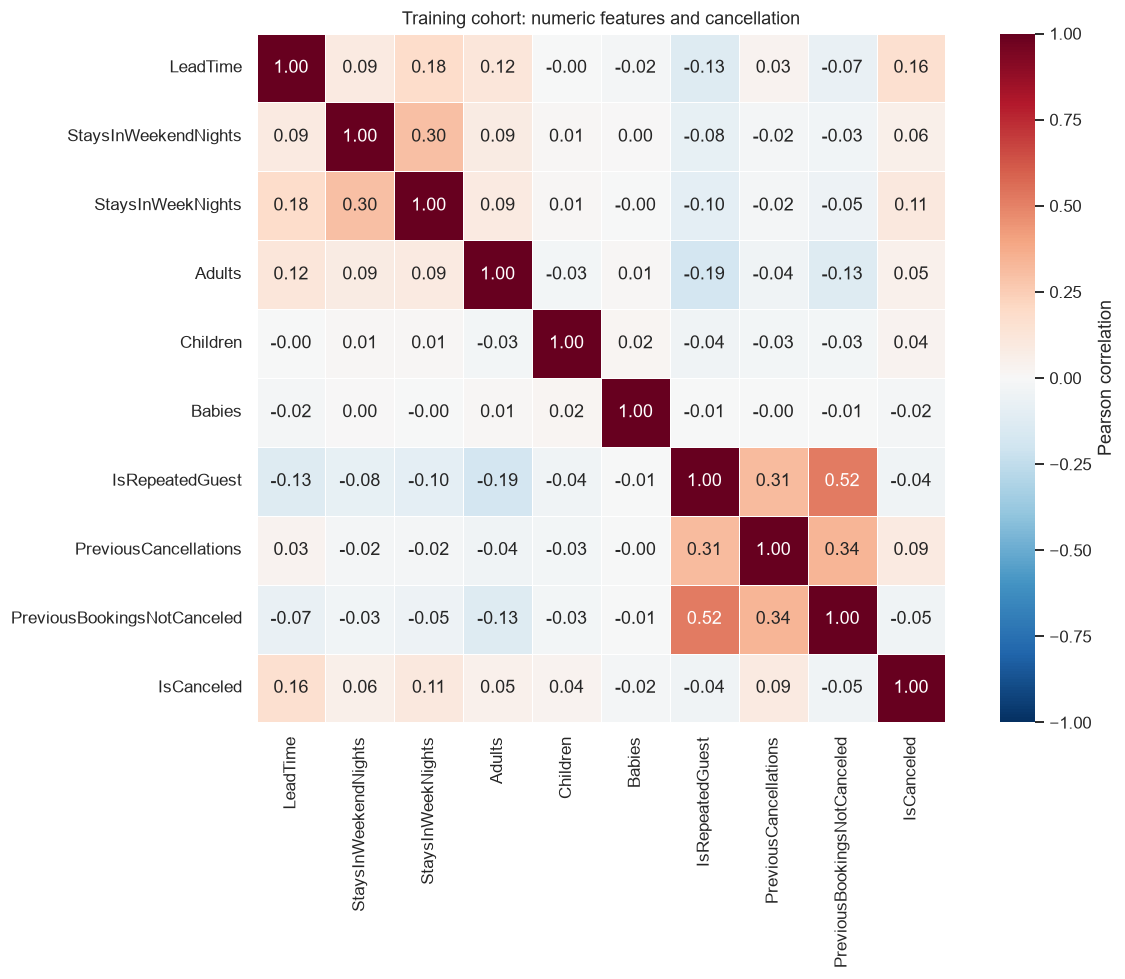

,Correlation with cancellation
PreviousBookingsNotCanceled,-0.045516
IsRepeatedGuest,-0.041048
Babies,-0.016893
Children,0.035764
Adults,0.053253
StaysInWeekendNights,0.058770
PreviousCancellations,0.091362
StaysInWeekNights,0.106891
LeadTime,0.162526


In [5]:
heatmap_columns = NUMERIC + ['IsCanceled']
correlations = eda[heatmap_columns].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, ax=ax, cbar_kws={'label': 'Pearson correlation'})
ax.set_title('Training cohort: numeric features and cancellation')
finish_plot('numeric_correlation_heatmap')
display(correlations['IsCanceled'].drop('IsCanceled').sort_values().to_frame('Correlation with cancellation'))

## 5. How cancellation rate varies across main numeric features
Use fixed, readable bins for plotting only. The model still receives the original numeric values. Each point shows the cancellation fraction within a group; labels show its sample count. Error bars are descriptive 95% Wilson binomial intervals. They do not account for dependent bookings or multiple comparisons.

Lead-time bins check whether advance bookings differ from last-minute bookings. Separate weekday/weekend stay counts explore duration patterns without creating a total-stay feature. Prior cancellations explore historical behavior. Small groups require caution.

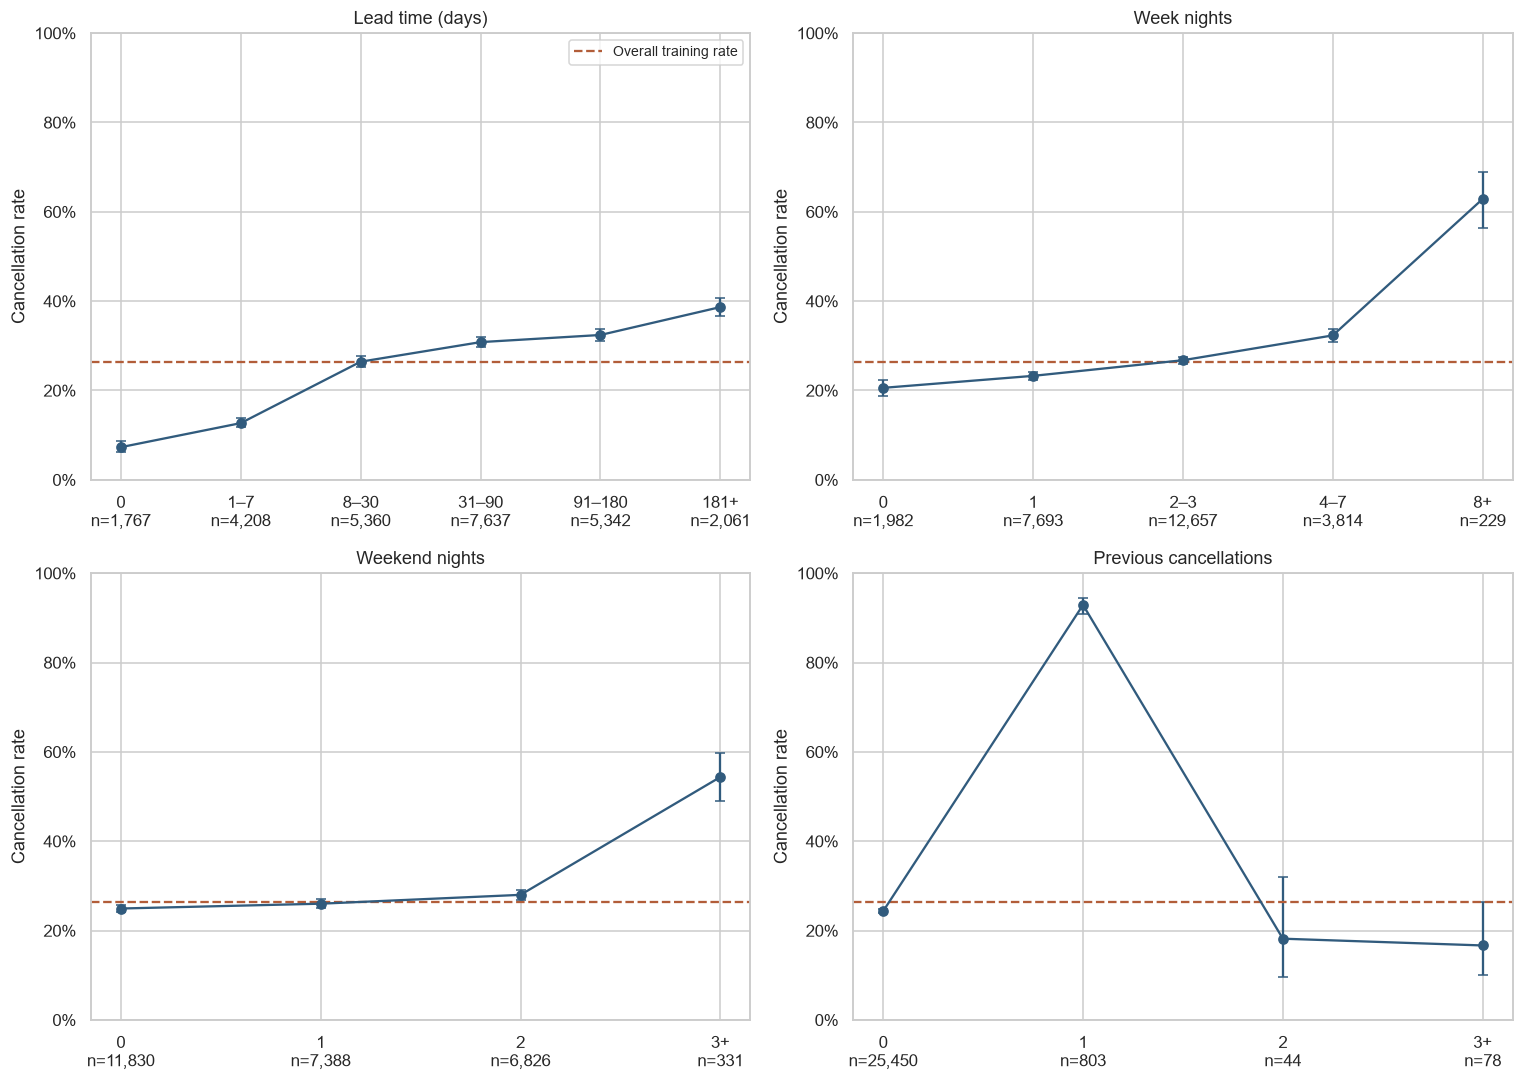

,bookings,cancellations,rate,lower,upper
LeadTime,,,,,
0,1767,129,0.0730,0.0618,0.0861
1–7,4208,534,0.1269,0.1172,0.1373
8–30,5360,1417,0.2644,0.2527,0.2763
31–90,7637,2354,0.3082,0.2980,0.3187
91–180,5342,1732,0.3242,0.3118,0.3369
181+,2061,797,0.3867,0.3659,0.4079


,bookings,cancellations,rate,lower,upper
StaysInWeekNights,,,,,
0,1982,408,0.2059,0.1886,0.2242
1,7693,1790,0.2327,0.2234,0.2423
2–3,12657,3388,0.2677,0.2600,0.2755
4–7,3814,1233,0.3233,0.3086,0.3383
8+,229,144,0.6288,0.5646,0.6888


,bookings,cancellations,rate,lower,upper
StaysInWeekendNights,,,,,
0,11830,2950,0.2494,0.2417,0.2572
1,7388,1922,0.2602,0.2503,0.2703
2,6826,1911,0.2800,0.2694,0.2907
3+,331,180,0.5438,0.4900,0.5967


,bookings,cancellations,rate,lower,upper
PreviousCancellations,,,,,
0,25450,6196,0.2435,0.2382,0.2488
1,803,746,0.9290,0.9091,0.9448
2,44,8,0.1818,0.0951,0.3196
3+,78,13,0.1667,0.1001,0.2646


Lead time (days)
Week nights
Weekend nights
Previous cancellations


In [6]:
def rate_table(groups):
    table = eda.groupby(groups, observed=True)['IsCanceled'].agg(bookings='size', cancellations='sum')
    table['rate'] = table.cancellations / table.bookings
    z = 1.96
    n, rate = table.bookings, table.rate
    center = (rate + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n))/(1+z*z/n)
    table['lower'], table['upper'] = center-half, center+half
    return table

def plot_rates(table, ax, title, horizontal=False):
    positions = np.arange(len(table))
    errors = np.vstack([table.rate-table.lower, table.upper-table.rate]).clip(min=0)
    if horizontal:
        ax.errorbar(table.rate, positions, xerr=errors, fmt='o', color='#315b7d', capsize=3)
        ax.set_yticks(positions, [f'{idx} (n={n:,})' for idx,n in zip(table.index,table.bookings)])
        ax.axvline(training_rate, color='#b25d39', linestyle='--', label='Overall training rate')
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_xlim(0,1); ax.set_xlabel('Cancellation rate')
    else:
        ax.errorbar(positions, table.rate, yerr=errors, fmt='o-', color='#315b7d', capsize=3)
        ax.set_xticks(positions, [f'{idx}\nn={n:,}' for idx,n in zip(table.index,table.bookings)])
        ax.axhline(training_rate, color='#b25d39', linestyle='--', label='Overall training rate')
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_ylim(0,1); ax.set_ylabel('Cancellation rate')
    ax.set_title(title)

numeric_groups = {
    'Lead time (days)': pd.cut(eda.LeadTime, [-1,0,7,30,90,180,np.inf], labels=['0','1–7','8–30','31–90','91–180','181+']),
    'Week nights': pd.cut(eda.StaysInWeekNights, [-1,0,1,3,7,np.inf], labels=['0','1','2–3','4–7','8+']),
    'Weekend nights': pd.cut(eda.StaysInWeekendNights, [-1,0,1,2,np.inf], labels=['0','1','2','3+']),
    'Previous cancellations': pd.cut(eda.PreviousCancellations, [-1,0,1,2,np.inf], labels=['0','1','2','3+']),
}
numeric_tables = {name: rate_table(groups) for name,groups in numeric_groups.items()}
fig, axes = plt.subplots(2,2,figsize=(14,10))
for ax,(name,table) in zip(axes.flat,numeric_tables.items()):
    plot_rates(table,ax,name)
axes[0,0].legend(fontsize=9)
finish_plot('numeric_cancellation_rates')
for name,table in numeric_tables.items():
    print(name); display(table.round(4))

## 6. Categories and cancellation
Compare market segment, deposit type, distribution channel, customer type, reserved room type, and repeat-guest status. Counts appear beside each category; intervals become wide when evidence is limited.

These are unadjusted associations. For example, deposit types can be linked to different customer populations or booking policies. A high cancellation rate does not mean the deposit policy caused cancellation. Near-perfect associations should trigger an availability/data-quality review before being trusted.

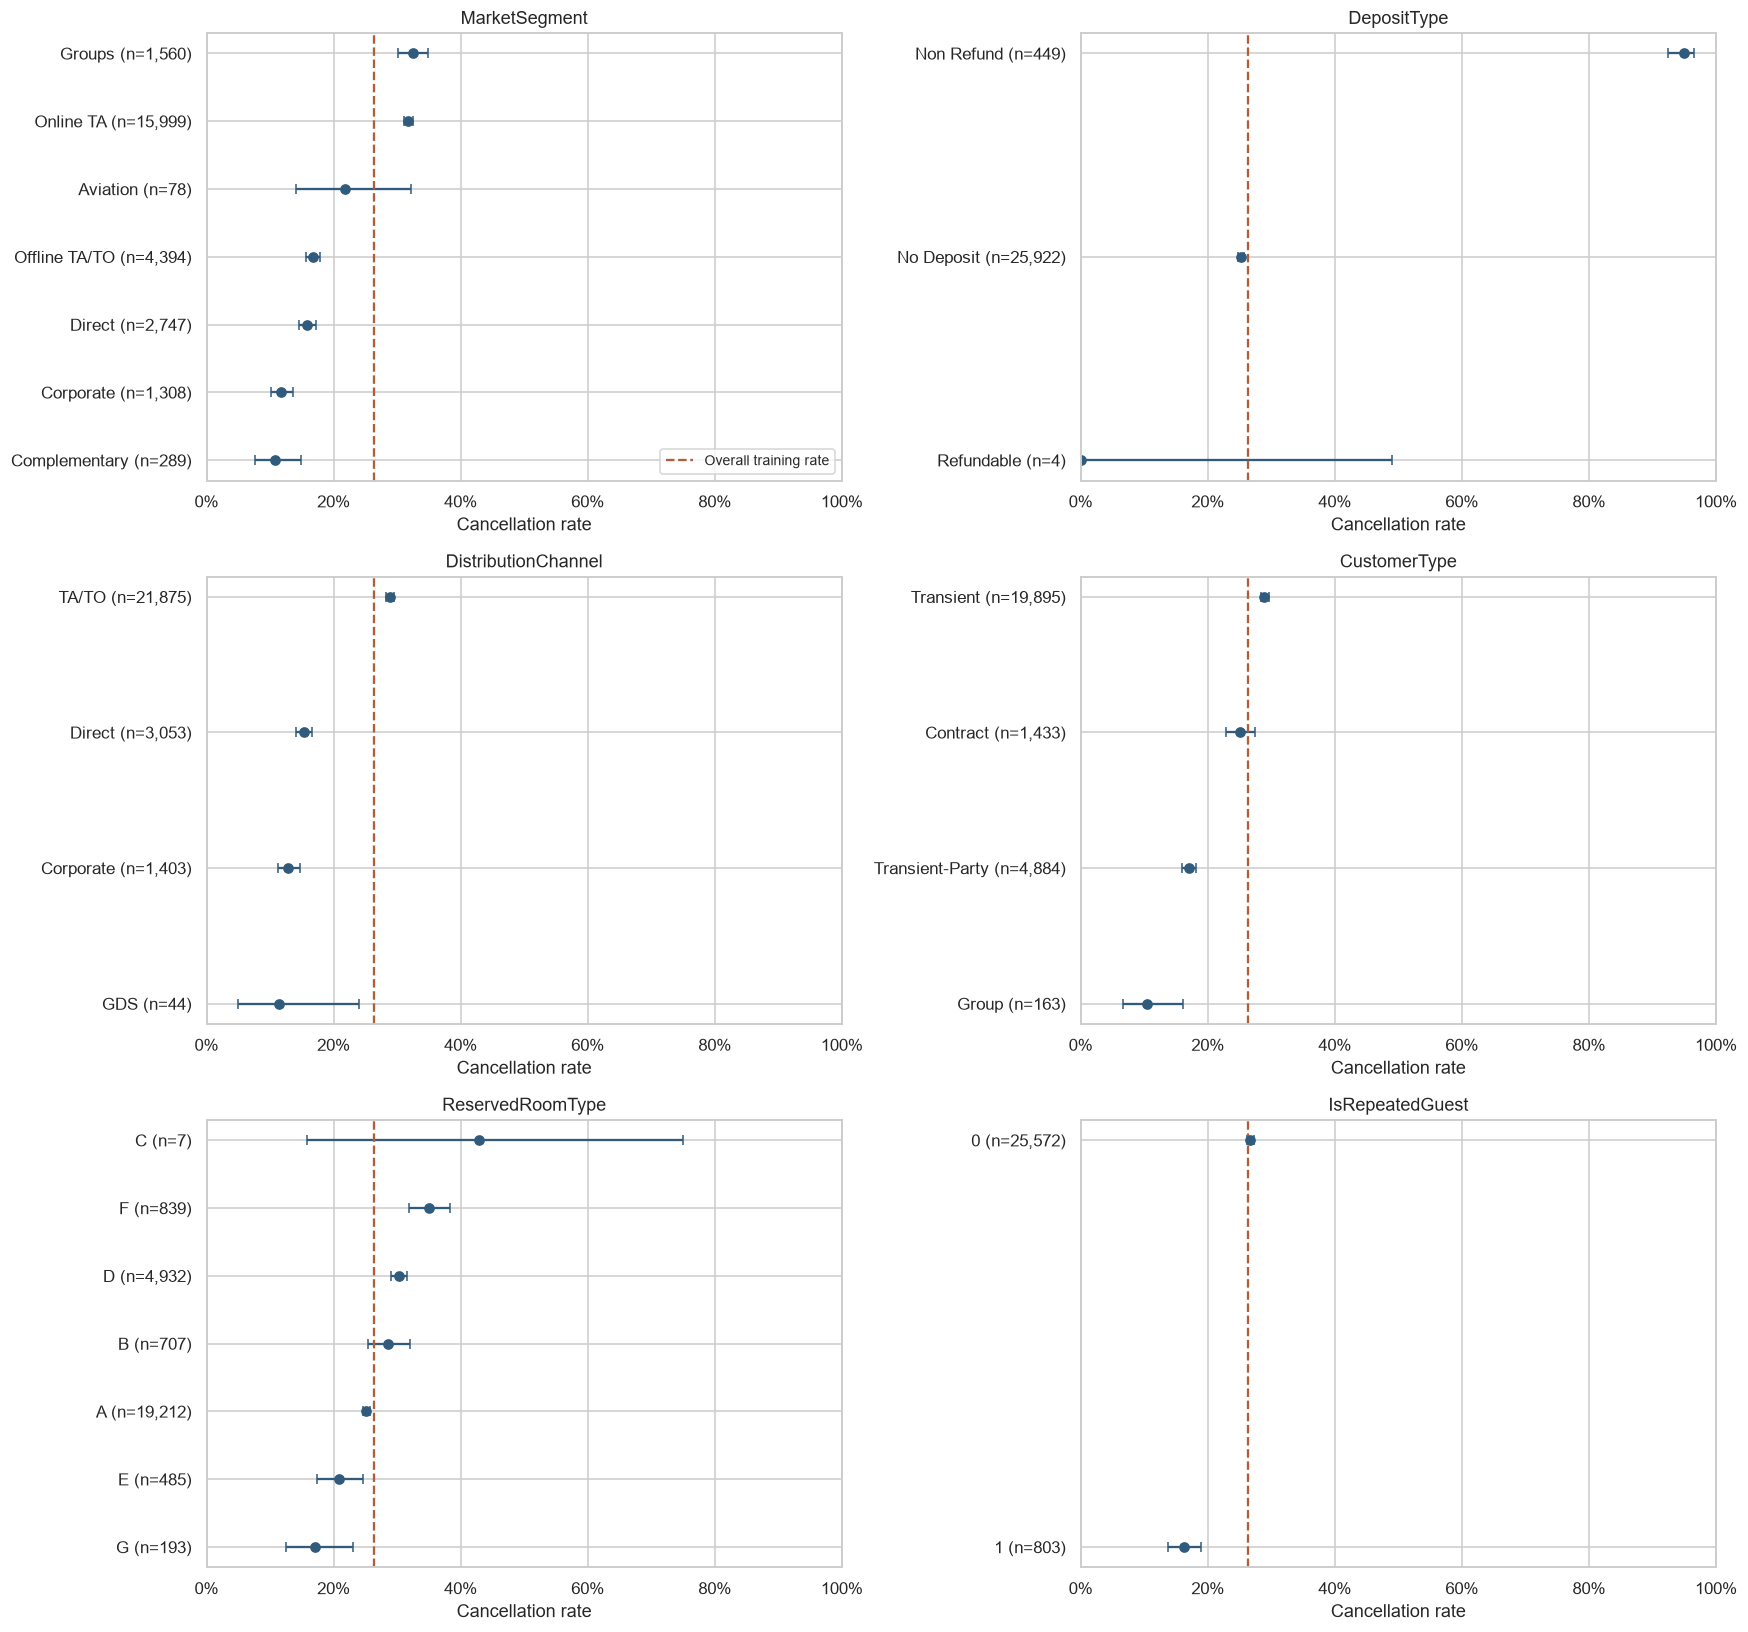

,bookings,cancellations,rate,lower,upper
MarketSegment,,,,,
Complementary,289,31,0.1073,0.0766,0.1482
Corporate,1308,154,0.1177,0.1014,0.1363
Direct,2747,434,0.1580,0.1448,0.1721
Offline TA/TO,4394,737,0.1677,0.1570,0.1791
Aviation,78,17,0.2179,0.1408,0.3216
Online TA,15999,5084,0.3178,0.3106,0.3250
Groups,1560,506,0.3244,0.3016,0.3480


,bookings,cancellations,rate,lower,upper
DepositType,,,,,
Refundable,4,0,0.0000,0.0000,0.4899
No Deposit,25922,6537,0.2522,0.2469,0.2575
Non Refund,449,426,0.9488,0.9243,0.9656


,bookings,cancellations,rate,lower,upper
DistributionChannel,,,,,
GDS,44,5,0.1136,0.0495,0.2398
Corporate,1403,181,0.1290,0.1125,0.1476
Direct,3053,467,0.1530,0.1406,0.1662
TA/TO,21875,6310,0.2885,0.2825,0.2945


,bookings,cancellations,rate,lower,upper
CustomerType,,,,,
Group,163,17,0.1043,0.0661,0.1607
Transient-Party,4884,832,0.1704,0.1601,0.1812
Contract,1433,359,0.2505,0.2288,0.2736
Transient,19895,5755,0.2893,0.2830,0.2956


,bookings,cancellations,rate,lower,upper
ReservedRoomType,,,,,
G,193,33,0.1710,0.1244,0.2304
E,485,101,0.2082,0.1745,0.2466
A,19212,4836,0.2517,0.2456,0.2579
B,707,202,0.2857,0.2536,0.3201
D,4932,1494,0.3029,0.2903,0.3159
F,839,294,0.3504,0.3189,0.3833
C,7,3,0.4286,0.1582,0.7495


,bookings,cancellations,rate,lower,upper
IsRepeatedGuest,,,,,
1,803,130,0.1619,0.1380,0.1890
0,25572,6833,0.2672,0.2618,0.2727


MarketSegment
DepositType
DistributionChannel
CustomerType
ReservedRoomType
IsRepeatedGuest


In [7]:
category_columns = ['MarketSegment','DepositType','DistributionChannel','CustomerType','ReservedRoomType','IsRepeatedGuest']
category_tables = {col: rate_table(eda[col]).sort_values('rate') for col in category_columns}
fig, axes = plt.subplots(3,2,figsize=(16,15))
for ax,(col,table) in zip(axes.flat,category_tables.items()):
    plot_rates(table,ax,col,horizontal=True)
axes[0,0].legend(fontsize=9, loc='lower right')
finish_plot('categorical_cancellation_rates')
for name,table in category_tables.items():
    print(name); display(table.round(4))

## 7. Arrival-month seasonality
Monthly rate and volume are shown together. These are the intended arrival months of training bookings, not the months when cancellation occurred. The chronological cutoff and maturity filtering mean months have unequal coverage; this is not a clean causal estimate of seasonality.

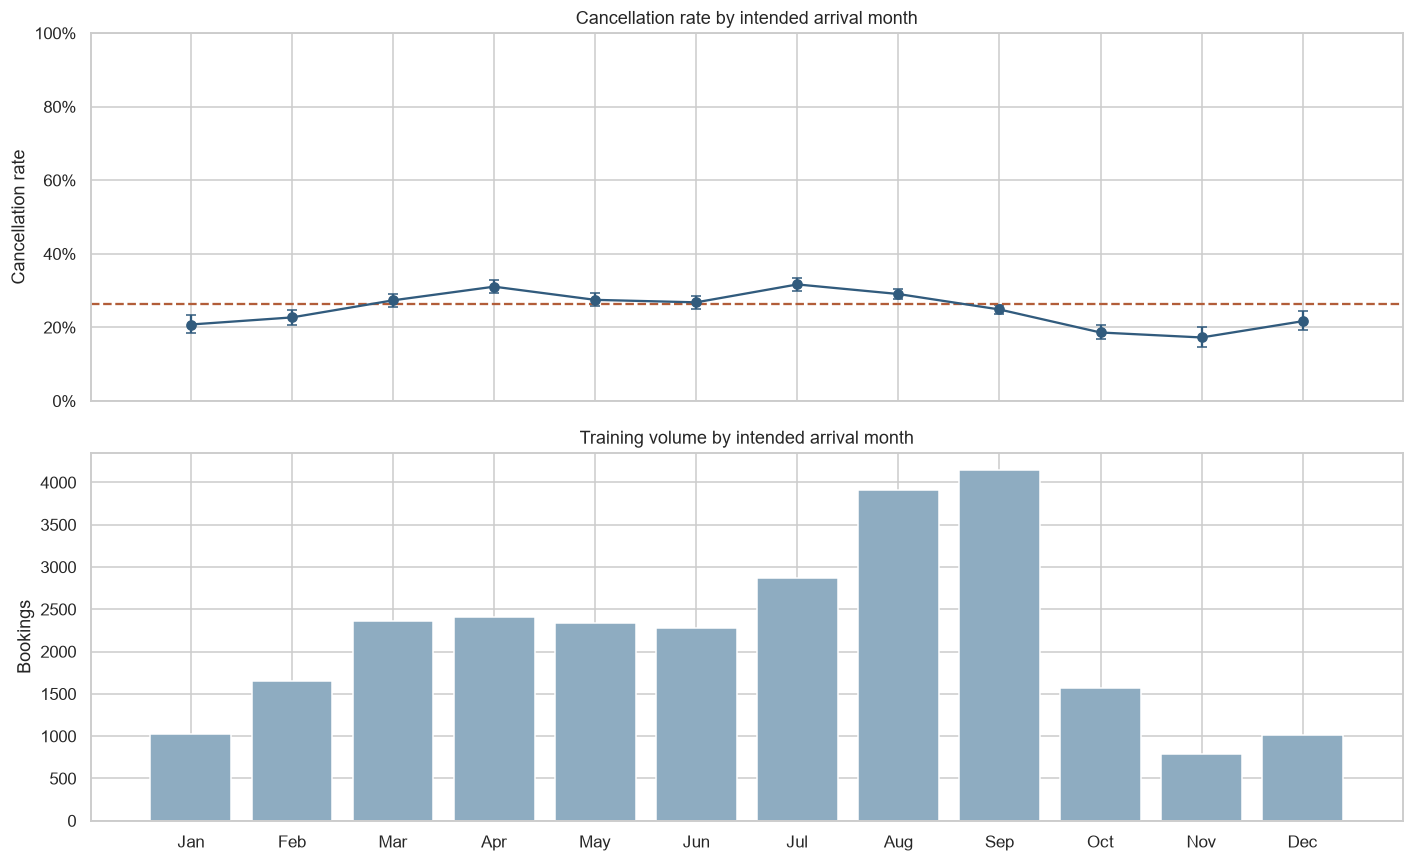

In [8]:
month_order = list(calendar.month_name)[1:]
month_table = rate_table(eda.ArrivalDateMonth).reindex(month_order).dropna(subset=['bookings'])
fig, axes = plt.subplots(2,1,figsize=(13,8),sharex=True)
plot_rates(month_table,axes[0],'Cancellation rate by intended arrival month')
axes[1].bar(np.arange(len(month_table)),month_table.bookings,color='#8eacc1')
axes[1].set(ylabel='Bookings',title='Training volume by intended arrival month')
axes[1].set_xticks(np.arange(len(month_table)),[str(x)[:3] for x in month_table.index])
finish_plot('arrival_month_rates')

## 8. Read the findings conservatively
The summaries below are computed from this run. Rates describe groups, not adjusted model effects. They do not rank causal influence. Correlated inputs and small groups can change the apparent relationships.

Data limitation inherited from general EDA: zero-guest bookings were removed only when not canceled. That target-dependent rule can bias this analysis even without a zero-guest feature. Deduplication without booking IDs can remove genuine identical bookings. Correct those upstream decisions before production conclusions; this notebook does not change general EDA.

In [9]:
strongest = correlations['IsCanceled'].drop('IsCanceled').dropna().abs().idxmax()
print(f'Training cancellation rate: {training_rate:.1%}.')
print(f'Largest absolute numeric correlation: {strongest} (r={correlations.loc[strongest,"IsCanceled"]:.3f}).')
for name,table in {**numeric_tables, **category_tables}.items():
    supported = table[table.bookings >= 100]
    if len(supported) >= 2:
        low,high = supported.rate.idxmin(),supported.rate.idxmax()
        print(f'{name}: among groups with at least 100 bookings, {low} has {supported.loc[low,"rate"]:.1%} canceled '
              f'and {high} has {supported.loc[high,"rate"]:.1%}.')
print('The 100-booking cutoff is a display aid, not a statistical significance test.')

Training cancellation rate: 26.4%.
Largest absolute numeric correlation: LeadTime (r=0.163).
Lead time (days): among groups with at least 100 bookings, 0 has 7.3% canceled and 181+ has 38.7%.
Week nights: among groups with at least 100 bookings, 0 has 20.6% canceled and 8+ has 62.9%.
Weekend nights: among groups with at least 100 bookings, 0 has 24.9% canceled and 3+ has 54.4%.
Previous cancellations: among groups with at least 100 bookings, 0 has 24.3% canceled and 1 has 92.9%.
MarketSegment: among groups with at least 100 bookings, Complementary has 10.7% canceled and Groups has 32.4%.
DepositType: among groups with at least 100 bookings, No Deposit has 25.2% canceled and Non Refund has 94.9%.
DistributionChannel: among groups with at least 100 bookings, Corporate has 12.9% canceled and TA/TO has 28.8%.
CustomerType: among groups with at least 100 bookings, Group has 10.4% canceled and Transient has 28.9%.
ReservedRoomType: among groups with at least 100 bookings, G has 17.1% cancele

## 9. Export CSVs for the modeling notebook
Save original, unscaled and unencoded inputs in `src/data/classification_features/basic/`.

- `train.csv`, `validation.csv`, `test.csv`: model inputs, `IsCanceled`, and `source_row_id`.
- `split_summary.csv`: cohort dates, sizes, and cancellation rates for reference.
- `plots/`: the EDA figures shown above.

The modeling notebook excludes the target and row ID from inputs and fits preprocessing only on training data. No NPZ, joblib, or JSON artifacts are required for this workflow.

In [2]:
for name, (features, target) in splits.items():
    exported = features.assign(IsCanceled=target)
    exported.index.name = 'source_row_id'
    exported.to_csv(OUTPUT_DIR / f'{name}.csv')
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)
print('Saved CSVs to:', OUTPUT_DIR)
print('Next: open classification_model.ipynb')

NameError: name 'splits' is not defined